# Separate Master-cohort EDA — training outcomes only

This is the longitudinal, non-OTP-selected, Master-labeled seed cohort. No Bronze–Diamond data are pooled. Master status is not independently dated/verified. Rates are Global **Master+**, full patch 16.19, queue 420; no NA substitution. Prior notebooks already examined this cohort's held-out outcomes, but every descriptive outcome plot below uses **training rows only**.

Observed WR and mean raw matchup benchmark use identical rows. Wilson intervals are approximate and ignore repeated-player/shared-match dependence. Recorded season-history games are features; training Bernoulli observations are a different count. One training appearance does not mean a first-time champion pick.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
from IPython.display import display,Image
start=Path.cwd().resolve()
PROJECT_ROOT=next(p for p in [start,*start.parents] if (p/'hlr_model/master_cohort_modeling.py').is_file())
if str(PROJECT_ROOT) not in sys.path:sys.path.insert(0,str(PROJECT_ROOT))
from hlr_model import master_cohort_modeling as master
MASTER_ANALYSIS=PROJECT_ROOT/'hlr_model/data/analyses/master_cohort_mastery_v1/20261028T214327398991Z_4beeb7d4'
manifest=json.loads((MASTER_ANALYSIS/'preparation_manifest.json').read_text())
assert all(master.file_sha(MASTER_ANALYSIS/name)==h for name,h in manifest['output_sha256'].items())
played=pd.read_parquet(MASTER_ANALYSIS/'prepared_played.parquet')
prepared={'played':played}
audit=json.loads((MASTER_ANALYSIS/'source_audit.json').read_text())
print('Actual interpreter:',sys.executable)
print('Cohort:',audit['cohort_definition'])
print('Target players / usable players:',audit['target_players'],audit['usable_source_players'])
print('Benchmark:',audit['benchmark'])
print('History depth among players with targets:',audit['initial_history_actual_target_players'])


Actual interpreter: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/.venv-modeling/bin/python
Cohort: 200 deterministic seed-1619 draws from legacy Master-labeled seeds; no OTP-only filter; 15 have no target games.
Target players / usable players: 185 184
Benchmark: Global Master+ raw matchup percent / 100; NOT exact Master-only, NOT NA fallback, NOT tier-centered probability
History depth among players with targets: {'25%': 170.0, '50%': 170.0, '75%': 170.0, 'count': 185.0, 'max': 170.0, 'mean': 161.56216216216217, 'min': 46.0, 'std': 24.933774799144075}


## Source coverage, exclusions and repeated-observation support

In [2]:
for name in ['split_support','usable_split_support','exclusions','training_support','training_group_support']:
    print(name);display(pd.read_parquet(MASTER_ANALYSIS/(name+'.parquet')))
print('Global benchmark statuses:',played.global_status.value_counts().to_dict())
print('No missing benchmark is replaced with .50.')


split_support


,split,rows,players,matches,usable_rows
0,purged_train_boundary,11,11,11,11
1,purged_validation_boundary,16,16,16,16
2,test,1067,128,1021,1065
3,train,5095,178,4753,5086
4,validation,1049,128,1005,1049


usable_split_support


,split,rows,players,matches
0,test,1065,127,1019
1,train,5086,177,4746
2,validation,1049,128,1005


exclusions


...

training_support


,training_games,players,player_champions,median_games_per_pc,fraction_pc_once,fraction_pc_lt5,players_n_ge50,players_n_ge100
0,5086,177,1388,1.0,0.554755,0.829251,111,65


training_group_support


,mastery_group,games,players,champions,median_experience,players_n_ge50,players_n_ge100
0,A,408,61,16,22.5,10,6
1,B,478,64,16,39.5,13,10
2,C,322,84,15,13.0,10,4
3,D,695,90,15,58.0,14,5
4,E,427,87,16,10.0,8,5
5,F,630,93,15,54.0,20,11
6,G,371,79,16,21.0,8,6
7,H,495,86,16,27.0,12,8
8,I,344,68,16,17.0,10,4
9,J,580,94,20,28.0,11,6


Global benchmark statuses: {'ok': 7232, 'unidentified_lane_opponent': 4, 'not_published_in_table': 2}
No missing benchmark is replaced with .50.


## Matched descriptive rates and group coverage

OTP rate means the current champion's share of strictly prior all-role games. Main means the existing count maximum, smallest ID on ties; there is no extra OTP cutoff for the main comparison. Categories show games and distinct players; the coverage heatmaps show both. All A–J/Unclassified memberships use the same pinned workbook method as the broad analysis.

,wins,games,players,baseline,observed_wr,ci_low,ci_high
experience_bin,,,,,,,
0,115,295,99,0.519093,0.389831,0.335933,0.446560
1–4,337,723,132,0.526307,0.466113,0.430026,0.502559
5–9,283,569,107,0.529282,0.497364,0.456437,0.538326
10–19,336,659,110,0.525357,0.509863,0.471750,0.547863
20–49,480,895,100,0.526980,0.536313,0.503556,0.568759
50+,994,1945,111,0.523401,0.511054,0.488839,0.533226


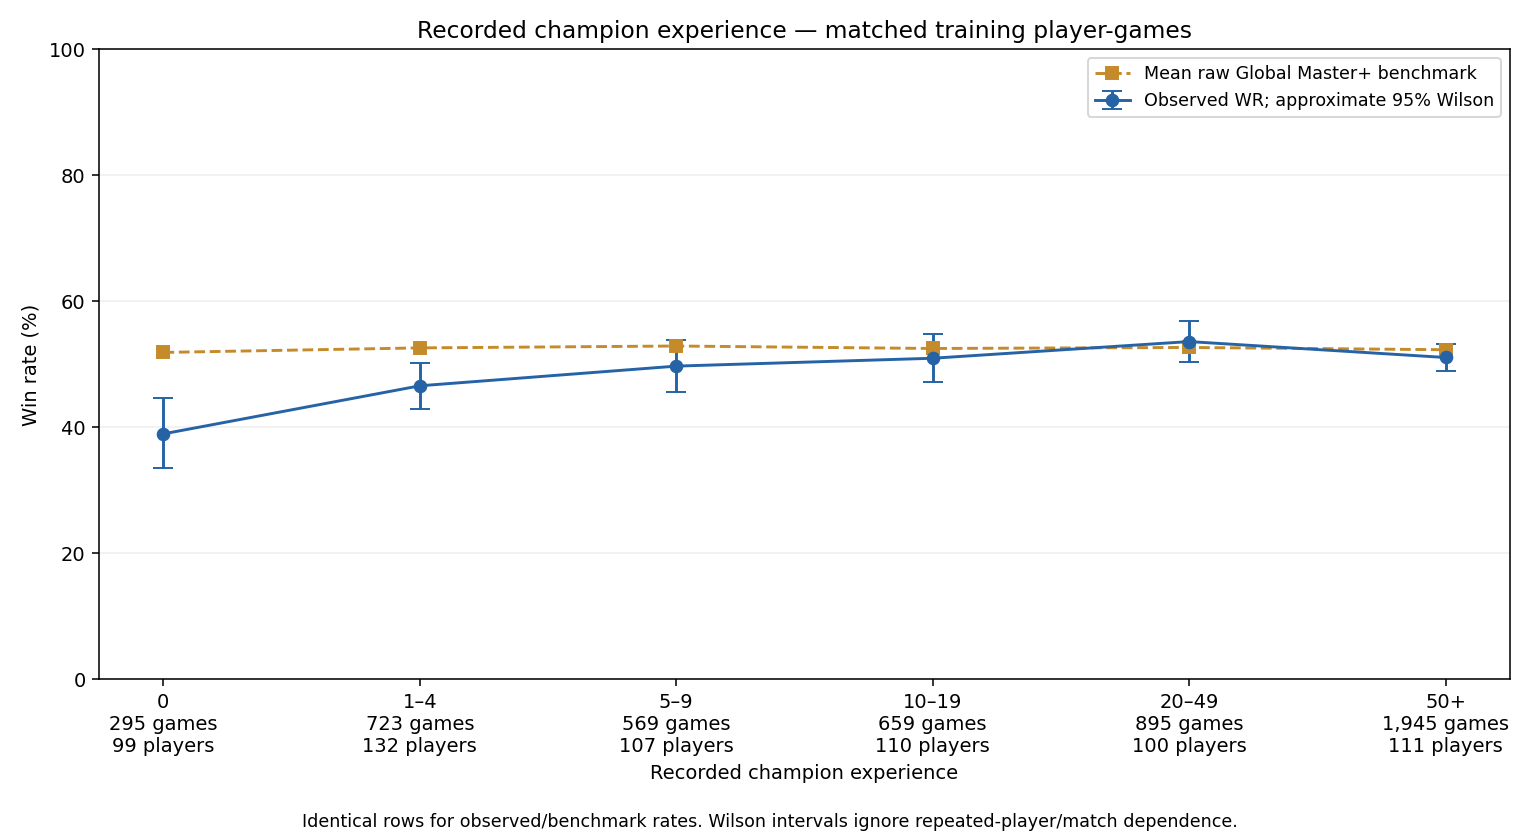

,wins,games,players,baseline,observed_wr,ci_low,ci_high
usage_bin,,,,,,,
0–20%,1386,2826,162,0.524879,0.490446,0.472040,0.508877
>20–40%,336,638,56,0.530322,0.526646,0.487859,0.565113
>40–60%,151,303,29,0.514178,0.498350,0.442426,0.554315
>60–80%,362,695,31,0.522005,0.520863,0.483710,0.557787
>80–100%,310,624,30,0.529557,0.496795,0.457705,0.535924


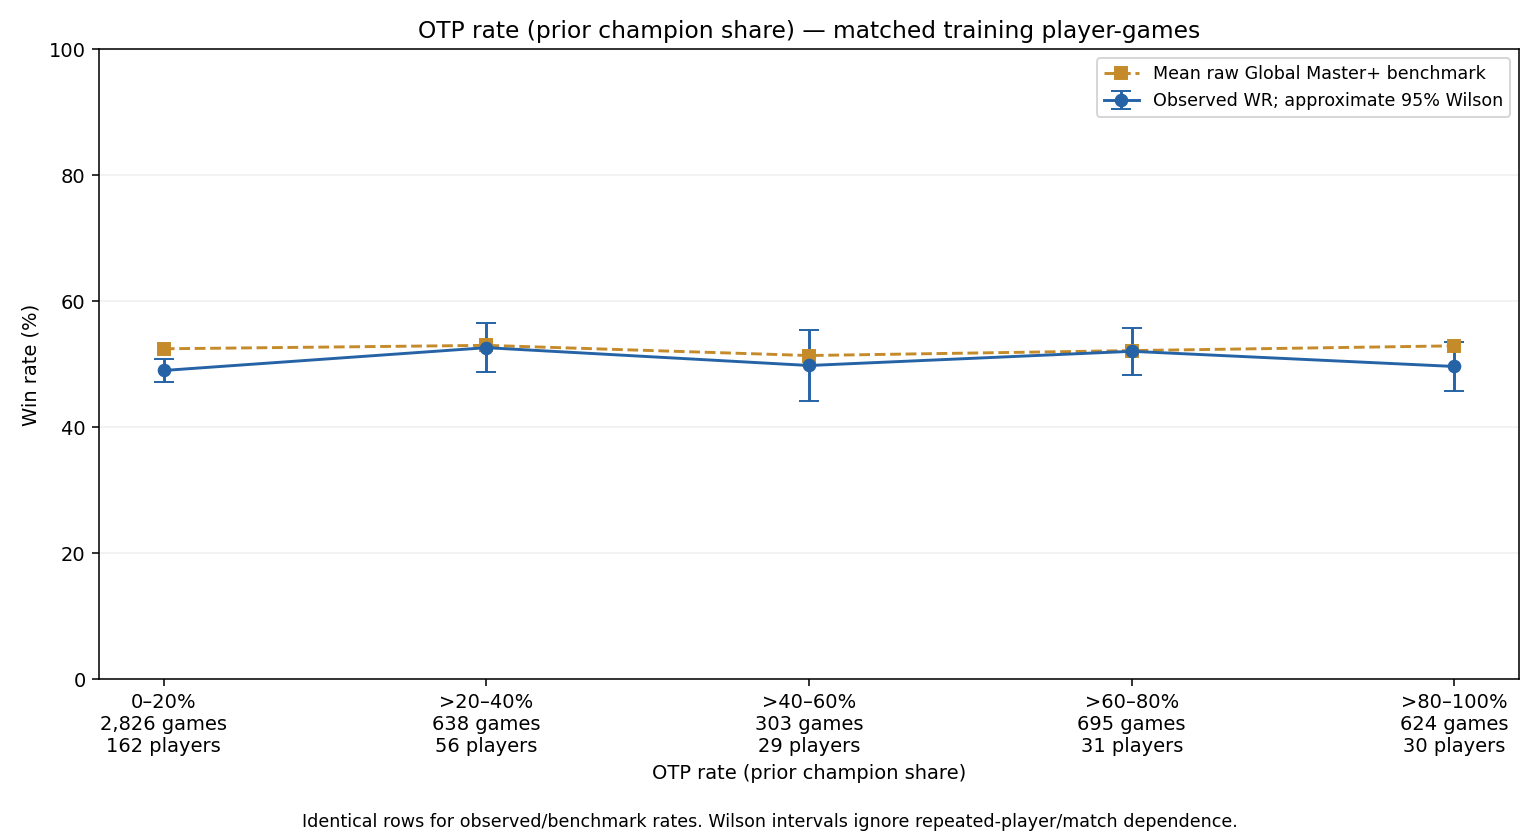

,wins,games,players,baseline,observed_wr,ci_low,ci_high
choice,,,,,,,
Another champion,1436,2933,166,0.525155,0.489601,0.471535,0.507694
Recorded main,1109,2153,155,0.525038,0.515095,0.493977,0.536160


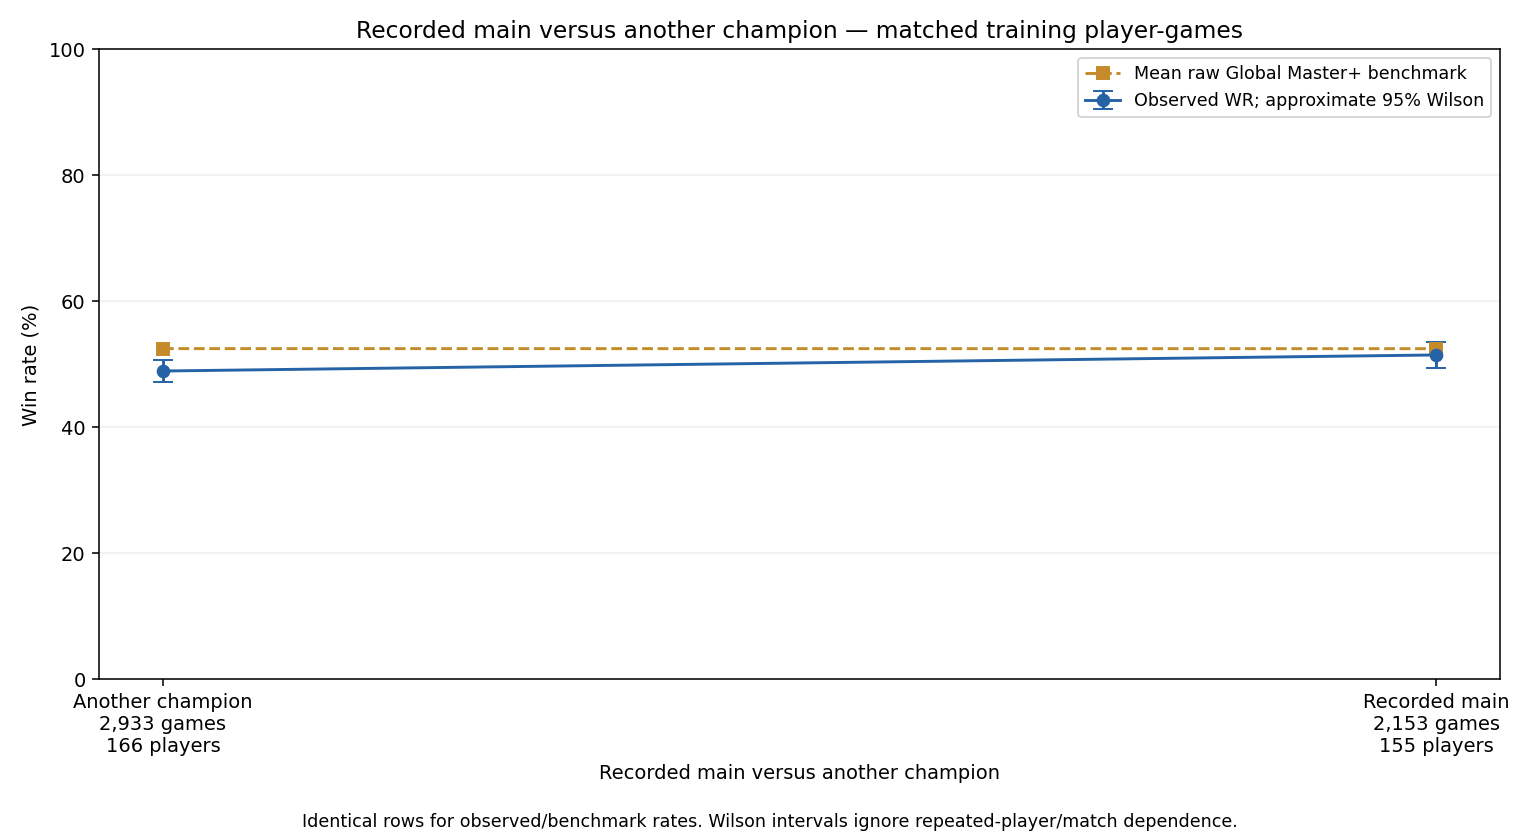

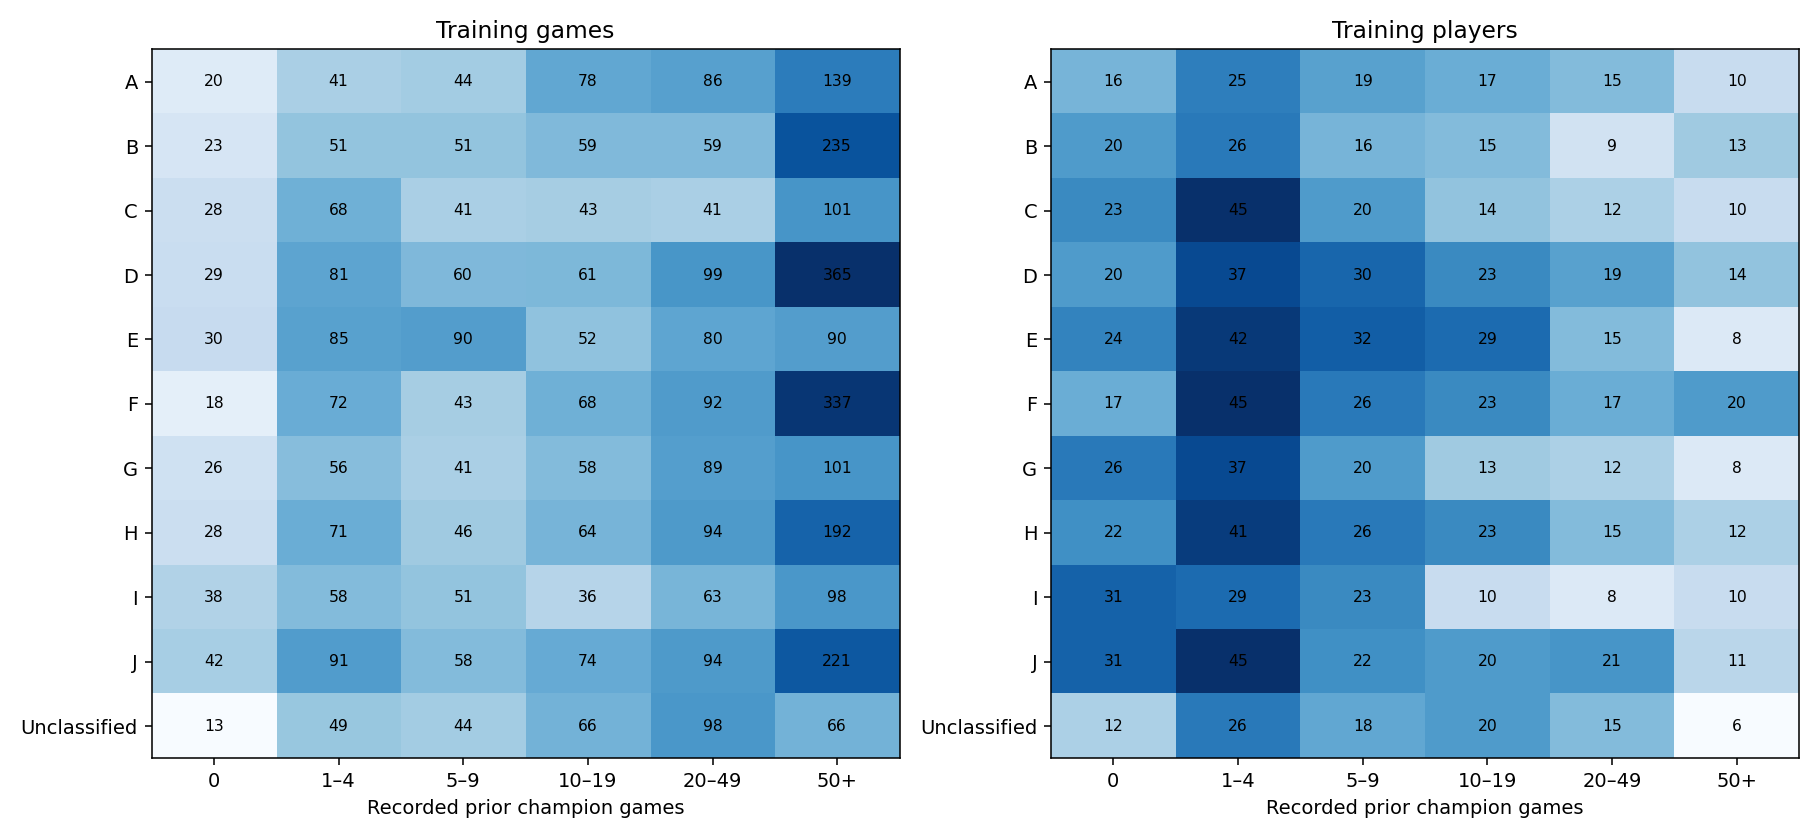

In [3]:
eda=master.eda_outputs(prepared,MASTER_ANALYSIS)
for key in ['experience','usage','main']:
    display(eda[key])
    display(Image(filename=str(MASTER_ANALYSIS/'figures'/('eda_'+key+'.png'))))
display(Image(filename=str(MASTER_ANALYSIS/'figures/eda_group_support.png')))


These descriptive plots do not adjust for champion/player selection or historical WR. Mean external rates are retrospective, benchmark-assisted comparisons. Sparse player coverage limits interpretation, especially at high experience. This EDA does not select model predictors, cutoffs or a preferred group ordering. See [master_cohort_modeling.ipynb](master_cohort_modeling.ipynb) for the prespecified exact NUTS fits and staged exposed-outcome assessment.

Roles are inferred from completed play, not verified pregame intent. Sampling is random within the inherited Master-labeled seed pool; that does not establish dated rank membership or a representative Master population. Full fitting/evaluation is complete in the separate modeling notebook; all EDA outcome plots remain training-only.